# 06 · PINO：从监督数据到 PDE 残差（高级）

**前置：** 03 和 05；自动微分、频谱微分。**目标：** 实现数据损失与物理损失，比较少标签 FNO 和物理约束 FNO。

解一维周期 $-u_{xx}+u=f$，训练输出 $v=Su$，$S=1+4\pi^2$。残差 $r=-v_{xx}+v-Sf$。与 PINN 为一个 PDE 实例拟合一个坐标函数不同，本章网络读取不同 forcing，学习整族 PDE 的算子。

PINO 原论文还研究更复杂 PDE 和多分辨率物理约束；这里展示核心思想的简化版本。参考：[PINO 原始论文](https://arxiv.org/abs/2111.03794)。

## 原理详解 A：监督学习、PINN 与 PINO 各自在拟合什么？

监督神经算子从多组函数对 $(f_i,u_i)$ 中拟合 $f\mapsto u$。PINN 的典型设置则针对一个 PDE 实例，用坐标网络 $u_\theta(x)$ 表示这一条解，并通过 PDE、边界和数据约束训练。若参数改变，通常需要再次求解或显式加入参数化结构。

PINO 在神经算子输入端保留不同函数实例，例如 $u_\theta(f)(x)$，又在输出端计算 PDE 残差。这样可同时利用已知解的标签和只有输入函数、没有解标签的实例。它学习的仍是函数族映射，而不只是一个实例的坐标拟合。

本章缩放解 $v=Su$ 满足
$$
\mathcal A v=Sf,\qquad\mathcal A=-\partial_{xx}+I.
$$
若没有监督标签，也可对大量 forcing 构造残差 $\mathcal A v_\theta(f)-Sf$。但物理约束是否能唯一确定解，还依赖边界、初值和方程性质。本章周期表示加反应项确保唯一；一般问题必须显式处理这些约束。

组合目标可写成
$$
L=L_{\rm data}+\lambda_{\rm phys}L_{\rm phys}
+\lambda_{\rm bc}L_{\rm bc}+\lambda_{\rm ic}L_{\rm ic}.
$$
本例不单独实现后两项：空间表示对应周期域，而且是稳态方程。对于时间 PDE，遗漏初值通常会使残差为零但解不正确。

来源：[PINO 原论文](https://arxiv.org/abs/2111.03794)。本章是其核心思路的简化示例。

## 原理详解 B：残差、误差与预条件的逐步推导

令真解为 $v_*$，预测误差为 $e=v_\theta-v_*$。由于 $\mathcal Av_*=Sf$，
$$
r=\mathcal Av_\theta-Sf=\mathcal Ae.
$$
频谱中 $d_k=1+(2\pi k)^2$，所以 $\widehat r_k=d_k\widehat e_k$。直接残差平方对误差模式施加权重 $d_k^2$，高频约按 $k^4$ 增长：
$$
\|r\|_{L^2}^2=\sum_kd_k^2|\widehat e_k|^2.
$$
即使高频解误差幅度很小，它也可能主导残差和梯度，造成优化尺度不平衡。

本章先解预条件残差
$$
\widetilde r=\mathcal A^{-1}r,\qquad
\widehat{\widetilde r}_k=\widehat r_k/d_k,
$$
再取 $L_{\rm phys}=\|\widetilde r\|_{L^2}^2$。于是
$$
\widetilde r=v_\theta-\mathcal A^{-1}(Sf)=v_\theta-v_*.
$$
代码的频谱除法恰好实现这个关系。因此对本线性可解析方程，物理损失与精确目标解的 MSE 数学等价。它避免了显式保存无标签函数的解，但并没有提供一种比解析求解更神奇的新信息。

对于非线性 PDE 或变系数方程，通常不能用同一个简单谱分母把残差变成解误差。预条件器也未必是算子的精确逆，必须重新分析。这个限制正是理解教程例子与研究级 PINO 的关键。

报告未经预条件的残差，能够检查网络是否真的接近满足原 PDE；只报告预条件损失，会隐藏高频导数误差。

## 原理详解 C：微分方式、损失尺度与公平对照

FNO 输出是规则网格上的值，适合对输出做 FFT 后谱微分。这里的自动微分用于将“网络 → FFT → 残差 → 损失”的梯度传播回参数，不是直接对网格索引求连续坐标导数。10 章的坐标网络则可对 x、y、z、t 直接用 autograd 求导。

损失相加之前应比较单位与尺度。若 $u$ 的单位是 U，forcing 的单位与微分算子有关，数据 MSE 和原始 PDE 残差 MSE 不一定能直接用相同权重。本章固定单位域、统一输出缩放，并使用逆算子预条件，使两项都对应 v 的平方误差尺度。一般问题需要无量纲化、归一化或有依据的权重设计。

baseline 与 PINO 具有相同初始化、标签采样序列、优化器和更新次数，但 PINO 额外处理 256 条无标签 forcing，并增加一次物理分支计算。相同更新次数不等于相同时间预算，也不等于相同输入信息。因此这里只解释“增加 PDE 约束样本后的变化”。

物理残差诊断还应配合边界条件、初始条件和解范数。某些方程的零函数或不正确的常数也能满足部分残差，但并不是给定条件下的解。本章反应项把这些自由度消除；不能把这个性质无条件推广到其他 PDE。

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "tutorial_utils.py").exists():
    ROOT = ROOT / "neural_operator_tutorials"
if not (ROOT / "tutorial_utils.py").exists():
    raise FileNotFoundError("Please start Jupyter in PINO or neural_operator_tutorials")
sys.path.insert(0, str(ROOT))
import torch
get_ipython().run_line_magic('matplotlib', 'inline')
from tutorial_utils import *
seed_all()
print("device:", DEVICE, "| smoke:", SMOKE)


device: cpu | smoke: False


## 1. 少量有标签函数 + 更多无标签 forcing

无标签函数只向物理损失提供 $f$，训练期间不生成或使用它们的解。验证、测试函数与两种训练数据都独立。解析解用于有标签训练样本，以及独立验证和最后测试。

In [2]:
SCALE = 1+4*torch.pi**2
x = torch.arange(64)/64
nphysics,ntest = counts(256,64)
nlabel = 8 if SMOKE else 16
flabel = periodic_data(torch.randn(nlabel,10),x)
fphysics = periodic_data(torch.randn(nphysics,10),x)
fval = periodic_data(torch.randn(ntest,10),x)
ftest = periodic_data(torch.randn(ntest,10),x)
def denominator(n,device,dtype):
    wave = 2*torch.pi*torch.fft.rfftfreq(n,d=1/n,device=device,dtype=dtype)
    return 1+wave.square()
def exact_scaled(f):
    d = denominator(f.shape[-1],f.device,f.dtype)
    return SCALE*torch.fft.irfft(torch.fft.rfft(f)/d,n=f.shape[-1])
vlabel,vval,vtest = exact_scaled(flabel),exact_scaled(fval),exact_scaled(ftest)
print("labeled:",nlabel,"unlabeled:",nphysics,"validation:",ntest,"test:",ntest)

labeled: 16 unlabeled: 256 validation: 64 test: 64


## 2. 频谱微分与残差预条件

$\widehat{v_{xx}}_k=-(2\pi k)^2\widehat v_k$。直接最小化残差平方会给高频误差施加 $k^4$ 权重，优化可能困难。我们使用 $H^{-2}$ 风格的预条件残差：先将频谱残差除以 $1+(2\pi k)^2$，再逆变换算均方损失；另外报告未经预条件的物理残差。

**特别说明：** 对本章可解析的线性 PDE，预条件残差恰好等于 $v-v_{\mathrm{exact}}$。因此这里的物理损失数学上等价于给无标签 forcing 一个由 PDE 决定的目标。它演示了 PDE 约束的实现，而不是证明在复杂 PDE 上具有普遍优势。

In [3]:
def residual(v,f):
    n = v.shape[-1]
    d = denominator(n,v.device,v.dtype)
    return torch.fft.irfft(d*torch.fft.rfft(v)-SCALE*torch.fft.rfft(f),n=n)
def physics_loss(v,f):
    n = v.shape[-1]
    d = denominator(n,v.device,v.dtype)
    rf = d*torch.fft.rfft(v)-SCALE*torch.fft.rfft(f)
    preconditioned = torch.fft.irfft(rf/d,n=n)
    return preconditioned.square().mean()
assert physics_loss(vlabel,flabel)<1e-10
print("Exact solution raw residual RMS:",residual(vlabel,flabel).square().mean().sqrt().item())
# Verify the mathematical equivalence just discussed.
probe = torch.randn_like(flabel)
assert torch.allclose(physics_loss(probe,flabel),(probe-vlabel).square().mean(),atol=1e-5)

Exact solution raw residual RMS: 0.0024452812504023314


In [4]:
class SpectralConv1d(nn.Module):
    """[batch, in_channels, N] -> [batch, out_channels, N]."""
    def __init__(self, cin, cout, modes):
        super().__init__()
        self.modes = modes
        self.weight = nn.Parameter(
            torch.randn(cin, cout, modes, dtype=torch.cfloat) / (cin*cout)**0.5)

    def forward(self, v):
        n = v.shape[-1]
        vf = torch.fft.rfft(v, dim=-1)
        m = min(self.modes, vf.shape[-1])
        out = torch.zeros(v.shape[0], self.weight.shape[1], vf.shape[-1],
                          dtype=vf.dtype, device=v.device)
        out[..., :m] = torch.einsum("bim,iom->bom", vf[..., :m], self.weight[..., :m])
        # Always specify n: odd-length grids would otherwise reconstruct incorrectly.
        return torch.fft.irfft(out, n=n, dim=-1)

class FNO1d(nn.Module):
    def __init__(self, width=24, modes=10, depth=3):
        super().__init__()
        self.lift = nn.Linear(3, width)
        self.spectral = nn.ModuleList([SpectralConv1d(width, width, modes) for _ in range(depth)])
        self.local = nn.ModuleList([nn.Conv1d(width, width, 1) for _ in range(depth)])
        self.project = nn.Sequential(nn.Linear(width, 32), nn.GELU(), nn.Linear(32, 1))

    def forward(self, a):
        # a: [B,N]; periodic positional features avoid an artificial seam at x=1.
        x = torch.arange(a.shape[-1], device=a.device, dtype=a.dtype) / a.shape[-1]
        pos = torch.stack(((2*torch.pi*x).sin(), (2*torch.pi*x).cos()), -1)
        inp = torch.cat((a[..., None], pos[None].expand(len(a), -1, -1)), -1)
        v = self.lift(inp).transpose(1, 2)
        for spectral, local in zip(self.spectral, self.local):
            v = torch.nn.functional.gelu(spectral(v) + local(v))
        return self.project(v.transpose(1, 2)).squeeze(-1)


## 3. 对照实验：相同初始化、标签和更新次数

两种模型使用完全相同的初始权重、标签重采样序列、优化器设置和更新次数。baseline 只看 16 条标签；PINO 额外看无标签 forcing，因此每步计算量更高，也使用更多输入函数。结果不能视为相同总计算预算或相同信息量的比较。

损失 $L=L_{data}+\lambda L_{physics}$。固定 $\lambda=1$ 作为示例；验证只报告，不调权重。两个模型都输出缩放后的 v，因此两个损失的尺度一致。

In [5]:
import copy
base = FNO1d(width=24,modes=10)
initial_state = copy.deepcopy(base.state_dict())

def train_comparison(use_physics):
    seed_all(123)  # same shuffles and label sampling in both arms
    model = FNO1d(width=24,modes=10).to(DEVICE)
    model.load_state_dict(initial_state)
    optimizer = torch.optim.Adam(model.parameters(),lr=0.002)
    loader = DataLoader(TensorDataset(fphysics),batch_size=32,shuffle=True)
    labels,targets = flabel.to(DEVICE),vlabel.to(DEVICE)
    history = []
    for epoch in range(epochs(120)):
        model.train(); total = 0.
        for (fp,) in loader:
            idx = torch.randint(len(labels),(min(16,len(labels)),),device=DEVICE)
            optimizer.zero_grad()
            data_loss = (model(labels[idx])-targets[idx]).square().mean()
            loss = data_loss
            if use_physics:
                fp = fp.to(DEVICE)
                loss = loss+physics_loss(model(fp),fp)
            if not torch.isfinite(loss): raise FloatingPointError("Non-finite PINO loss")
            loss.backward(); optimizer.step(); total += loss.item()
        model.eval()
        with torch.no_grad():
            val = relative_l2(model(fval.to(DEVICE)),vval.to(DEVICE)).mean().item()
        history.append((total/len(loader),val))
        if epoch==0 or (epoch+1)%max(1,epochs(120)//4)==0:
            print("PINO" if use_physics else "Data",epoch+1,"loss",history[-1][0],"val",val)
    return model,np.asarray(history)
baseline,hbase = train_comparison(False)
pino,hpino = train_comparison(True)

Data 1 loss 1.017831064760685 val 0.9477388858795166


Data 30 loss 3.564487997209653e-05 val 0.01778404973447323


Data 60 loss 1.0139975074707763e-05 val 0.013334454037249088


Data 90 loss 4.067424043796564e-06 val 0.01145730260759592


Data 120 loss 1.7811637604836505e-06 val 0.010221550241112709


PINO 1 loss 2.0030564963817596 val 0.937140703201294


PINO 30 loss 6.833504312453442e-05 val 0.00972303282469511


PINO 60 loss 2.51609862971236e-05 val 0.005970373749732971


PINO 90 loss 1.3111749467498157e-05 val 0.004426795057952404


PINO 120 loss 8.558904653455102e-06 val 0.0035481913946568966


## 4. 同时检查解误差与物理残差

残差包含二阶微分，可能放大网络的小高频误差。低解误差不保证低残差；低残差通常也需要边界条件和唯一性。本例周期表示自然对应周期网格，反应项保证唯一性。

Test relative L2: mean=0.0081, median=0.0067, max=0.0261
Test relative L2: mean=0.0025, median=0.0022, max=0.0073
Data relative solution L2 0.008123896084725857 raw relative PDE residual 0.08141997456550598
PINO relative solution L2 0.002541537396609783 raw relative PDE residual 0.03575789928436279


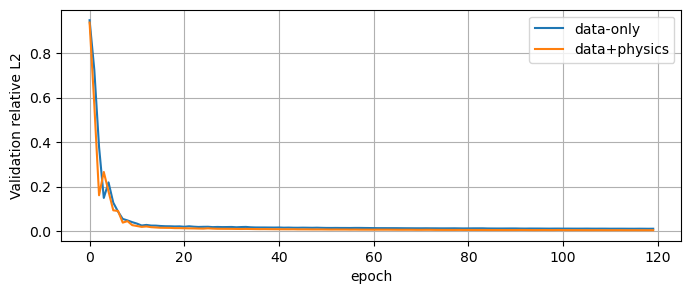

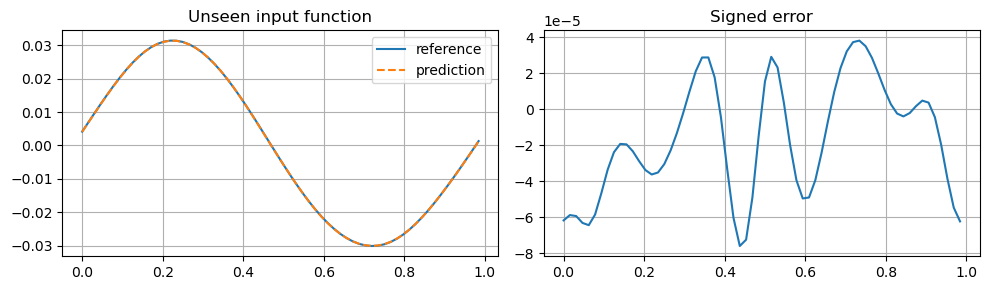

In [6]:
pred_base,err_base = report(baseline,ftest,vtest)
pred_pino,err_pino = report(pino,ftest,vtest)
for name,pred,err in [("Data",pred_base,err_base),("PINO",pred_pino,err_pino)]:
    r = residual(pred,ftest)
    relative_residual = r.reshape(ntest,-1).norm(dim=1)/(SCALE*ftest).norm(dim=1).clamp_min(1e-8)
    print(name,"relative solution L2",err.mean().item(),
          "raw relative PDE residual",relative_residual.mean().item())
plt.plot(hbase[:,1],label="data-only"); plt.plot(hpino[:,1],label="data+physics")
plt.xlabel("epoch"); plt.ylabel("Validation relative L2"); plt.legend(); plt.show()
plot_1d(x,vtest/SCALE,pred_pino/SCALE)

**练习：** ① 比较 $\lambda=0,0.1,1,10$，使用独立验证集选择后再测一次测试集；② 去掉预条件，观察高频残差与优化难度；③ 在 128 点无标签 forcing 上施加物理损失，保留 64 点监督标签；④ 改为变系数方程后，重新推导残差和边界条件。

**研究延伸：** 多分辨率物理损失、未知参数输入、复杂几何、时间推进、守恒结构。必须明确数据分布、参考求解器误差、计算预算和测试协议，再比较模型。

你现在已经完成从离散回归到函数查询、频谱卷积、非线性 PDE、二维场和物理约束的学习路线。